# Hafta 10 · CNN Mimarileri, Transfer Öğrenme ve Nesne Tespiti

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde önemli CNN mimarilerinin parametre ve işlem sayılarını karşılaştıracak, ResNet-50'nin katmanlarını izleyecek, artık bağlantının derin ağlarda neden gerekli olduğunu küçük bir deneyle görecek, ResNet-18 ile transfer öğrenmeyi hazırlayacak, torchvision ile veri artırma hattı kuracak ve IoU, NMS ve AP'yi kodlayacaksınız.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

## 1. Parametre tasarrufunu PyTorch ile doğrulamak (Çözümlü Örnek 10.1–10.3)
Bias terimleri ihmal edildiği için tüm katmanlar `bias=False` ile kuruldu.

In [2]:
import torch
from torch import nn

say = lambda m: sum(p.numel() for p in m.parameters())
conv = lambda i, o, k, **kw: nn.Conv2d(i, o, k, bias=False, **kw)

C = 64                                              # Örnek 10.1
iki = nn.Sequential(conv(C, C, 3), conv(C, C, 3))
print("iki 3x3:", say(iki), "| bir 5x5:", say(conv(C, C, 5)))

dogrudan = conv(256, 256, 3)                        # Örnek 10.2
darbogaz = nn.Sequential(conv(256, 64, 1), conv(64, 64, 3),
                         conv(64, 256, 1))
print("doğrudan:", say(dogrudan), "| darboğaz:", say(darbogaz))

ayr = nn.Sequential(conv(256, 256, 3, groups=256),  # Örnek 10.3
                    conv(256, 256, 1))
oran = say(dogrudan) / say(ayr)
print("ayrılabilir:", say(ayr), "| oran:", round(oran, 1))

iki 3x3: 73728 | bir 5x5: 102400
doğrudan: 589824 | darboğaz: 69632
ayrılabilir: 67840 | oran: 8.7


## 2. Mimarileri ölçmek: parametre ve işlem sayısı
`torch.device("meta")` modeli bellek ayırmadan yalnızca **şekilleriyle** kurar; ağırlık indirmeye ve gerçek hesap yapmaya gerek kalmadan parametreleri ve çarpma-toplama (MAC) sayısını sayabiliriz. 1 MAC = 2 FLOP (bir çarpma + bir toplama).

In [3]:
from torchvision import models
from torch.utils.flop_counter import FlopCounterMode

adlar = ["alexnet", "vgg16", "googlenet", "resnet18",
         "resnet34", "resnet50", "resnet101", "resnet152",
         "densenet121", "mobilenet_v2", "efficientnet_b0",
         "convnext_tiny", "vit_b_16"]
sonuc = {}
for ad in adlar:
    ek = {}
    if ad == "googlenet":                   # uyarı vermesin
        ek = dict(aux_logits=False, init_weights=False)
    with torch.device("meta"):              # yalnızca şekiller
        m = getattr(models, ad)(weights=None, **ek)
        x = torch.randn(1, 3, 224, 224)
    p = say(m) / 1e6                         # milyon parametre
    with FlopCounterMode(display=False) as sayac:
        m(x)
    mac = sayac.get_total_flops() / 2e9      # GMAC = FLOP / 2
    sonuc[ad] = (p, mac)
    print(f"{ad:15s}{p:6.1f} M {mac:6.2f} G")

alexnet          61.1 M   0.71 G
vgg16           138.4 M  15.47 G


googlenet         6.6 M   1.50 G
resnet18         11.7 M   1.81 G
resnet34         21.8 M   3.66 G


resnet50         25.6 M   4.09 G


resnet101        44.5 M   7.80 G


resnet152        60.2 M  11.51 G


densenet121       8.0 M   2.83 G


mobilenet_v2      3.5 M   0.30 G


efficientnet_b0   5.3 M   0.39 G
convnext_tiny    28.6 M   4.46 G


vit_b_16         86.6 M  17.56 G


Aynı sonuçları log ölçekli bir grafikte gösterelim: sağ üst = büyük ve pahalı, sol alt = küçük ve hızlı.

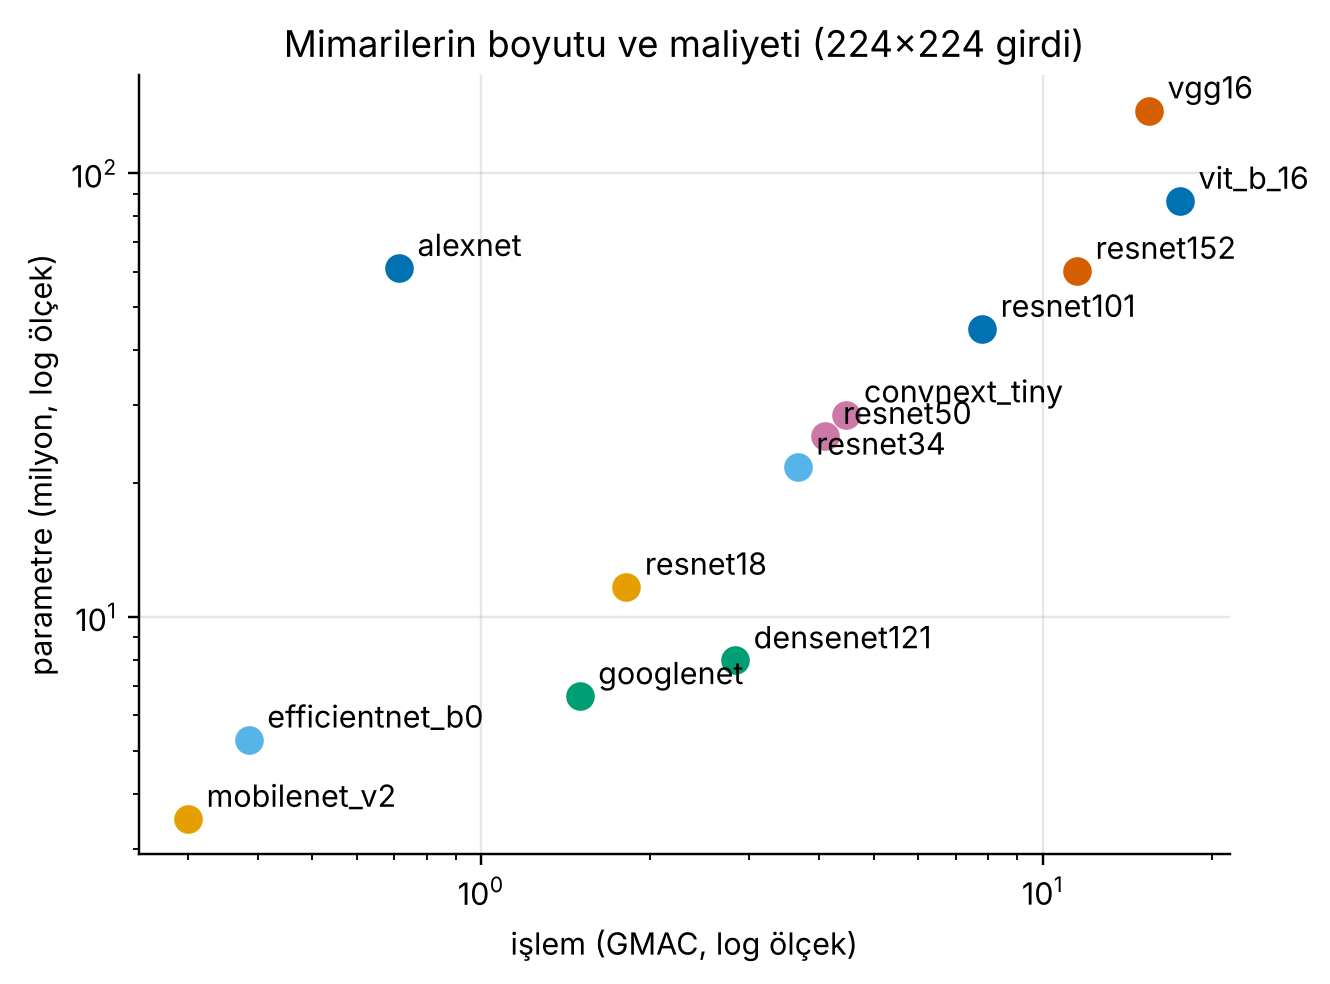

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for ad, (p, mac) in sonuc.items():
    ax.scatter(mac, p, s=70)
    ax.annotate(ad, (mac, p), textcoords="offset points",
                xytext=(6, 4), fontsize=10)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("işlem (GMAC, log ölçek)")
ax.set_ylabel("parametre (milyon, log ölçek)")
ax.set_title("Mimarilerin boyutu ve maliyeti (224×224 girdi)")
plt.show()

## 3. ResNet-50'nin içine bakmak
Bir görüntü ağın aşamalarından geçerken boyutu nasıl değişiyor? "50" nereden geliyor?

In [5]:
m = models.resnet50(weights=None).eval()  # aynı mimari
x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    x = m.maxpool(m.relu(m.bn1(m.conv1(x))))
    print("giriş  ", tuple(x.shape))
    for ad in ["layer1", "layer2", "layer3", "layer4"]:
        x = getattr(m, ad)(x)
        print(f"{ad:7s}", tuple(x.shape))
    x = torch.flatten(m.avgpool(x), 1)
    print("GAP    ", tuple(x.shape))
    print("fc     ", tuple(m.fc(x).shape))
b = [len(getattr(m, f"layer{i}")) for i in range(1, 5)]
print("bloklar:", b, "-> 1+3x16+1 =", 2 + 3 * sum(b))
conv = [k for k in m.modules() if isinstance(k, nn.Conv2d)]
print("Conv2d :", len(conv))

giriş   (1, 64, 56, 56)
layer1  (1, 256, 56, 56)
layer2  (1, 512, 28, 28)
layer3  (1, 1024, 14, 14)
layer4  (1, 2048, 7, 7)
GAP     (1, 2048)
fc      (1, 1000)
bloklar: [3, 4, 6, 3] -> 1+3x16+1 = 50
Conv2d : 53


## 4. Neden artık bağlantı? Küçük bir deney
25 bloktan (50 doğrusal katman) oluşan iki ağ kuruyoruz. Tek fark, bloğun çıktısına girdinin eklenip eklenmemesi.

In [6]:
class Blok(nn.Module):
    def __init__(self, d, artik):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, d))
        self.artik = artik
    def forward(self, x):
        y = self.f(x)
        return torch.relu(y + x) if self.artik else torch.relu(y)   # tek fark: "+ x"

def ag(artik, n_blok=25, d=32):            # 25 blok = 50 doğrusal katman
    return nn.Sequential(nn.Linear(8, d), nn.ReLU(),
                         *[Blok(d, artik) for _ in range(n_blok)], nn.Linear(d, 1))

torch.manual_seed(0)
X = torch.randn(512, 8)
y = X[:, :1] * X[:, 1:2] + torch.sin(X[:, 2:3])   # öğrenilecek fonksiyon

In [7]:
for artik in [False, True]:
    torch.manual_seed(1)
    model = ag(artik)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for adim in range(301):
        opt.zero_grad()
        kayip = nn.functional.mse_loss(model(X), y)
        kayip.backward()
        if adim == 0:                 # ilk katmanın gradyanı
            g = model[0].weight.grad.norm().item()
        opt.step()
    ad = "artık ağ" if artik else "düz ağ  "
    print(f"{ad}: gradyan {g:.1e} | kayıp {kayip.item():.4f}")

düz ağ  : gradyan 9.9e-23 | kayıp 1.4171


artık ağ: gradyan 2.6e-01 | kayıp 0.0010


## 5. ResNet-18 ile transfer öğrenme (4 sınıflı yaprak hastalığı problemi)
Bu hücre mimariyi `weights=None` ile kurar; parametre sayıları ve çıktı boyutları ağırlıklardan bağımsızdır. Gerçek bir projede ImageNet ağırlıklarını kullanın (aşağıdaki Colab hücresine bakın).

In [8]:
# Colab'da: weights=models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=None)   # aynı mimari
for p in model.parameters():            # tabanı dondur
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, 4)   # 512 -> 4

egitilebilir = lambda m: sum(p.numel() for p in m.parameters()
                             if p.requires_grad)
print("toplam      :", say(model))
print("eğitilebilir:", egitilebilir(model))     # 512*4 + 4

toplam      : 11178564
eğitilebilir: 2052


In [9]:
for p in model.layer4.parameters():     # ince ayar: son blok
    p.requires_grad = True
optimizator = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=1e-4)
print("eğitilebilir:", egitilebilir(model))
model.eval()
print(model(torch.randn(2, 3, 224, 224)).shape)  # 2 görüntü, 4 skor

eğitilebilir: 8395780


torch.Size([2, 4])


### Colab'da deneyin: ImageNet ağırlıklarıyla tahmin
Bu hücre ağırlıkları internetten indirir (~45 MB); Colab'da çalıştırın. Kedi fotoğrafı için en olası üç ImageNet sınıfını yazdırır. Eğitim döngüsü 7. haftadakiyle aynıdır.

In [ ]:
from PIL import Image
from skimage import data
kedi = Image.fromarray(data.chelsea())
agirliklar = models.ResNet18_Weights.DEFAULT
model_on = models.resnet18(weights=agirliklar).eval()   # önceden eğitilmiş ResNet-18
hazirla = agirliklar.transforms()                       # ağırlıklarla uyumlu test dönüşümü
with torch.no_grad():
    olas = model_on(hazirla(kedi).unsqueeze(0)).softmax(dim=1)[0]
deger, sinif = olas.topk(3)
for p, i in zip(deger, sinif):
    print(f"{agirliklar.meta['categories'][i]:>18s}  {p:.3f}")

## 6. torchvision ile veri artırma
Aşağıdaki yardımcı fonksiyon, normalize edilmiş görüntü tensörlerini ekranda gösterebilmek için normalizasyonu geri alır.

In [10]:
from torchvision import transforms
from PIL import Image
from skimage import data

def goster(tensorler, basliklar):
    """Normalize edilmiş görüntü tensörlerini 3 sütunlu bir ızgarada gösterir."""
    ort = torch.tensor(ORT).view(3, 1, 1)
    ss = torch.tensor(SS).view(3, 1, 1)
    fig, eksen = plt.subplots(2, 3, figsize=(7.5, 5.2))
    for ax, t, b in zip(eksen.flat, tensorler, basliklar):
        ax.imshow((t * ss + ort).permute(1, 2, 0).clamp(0, 1))
        ax.set_title(b)
    for ax in eksen.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

torch.Size([3, 224, 224])


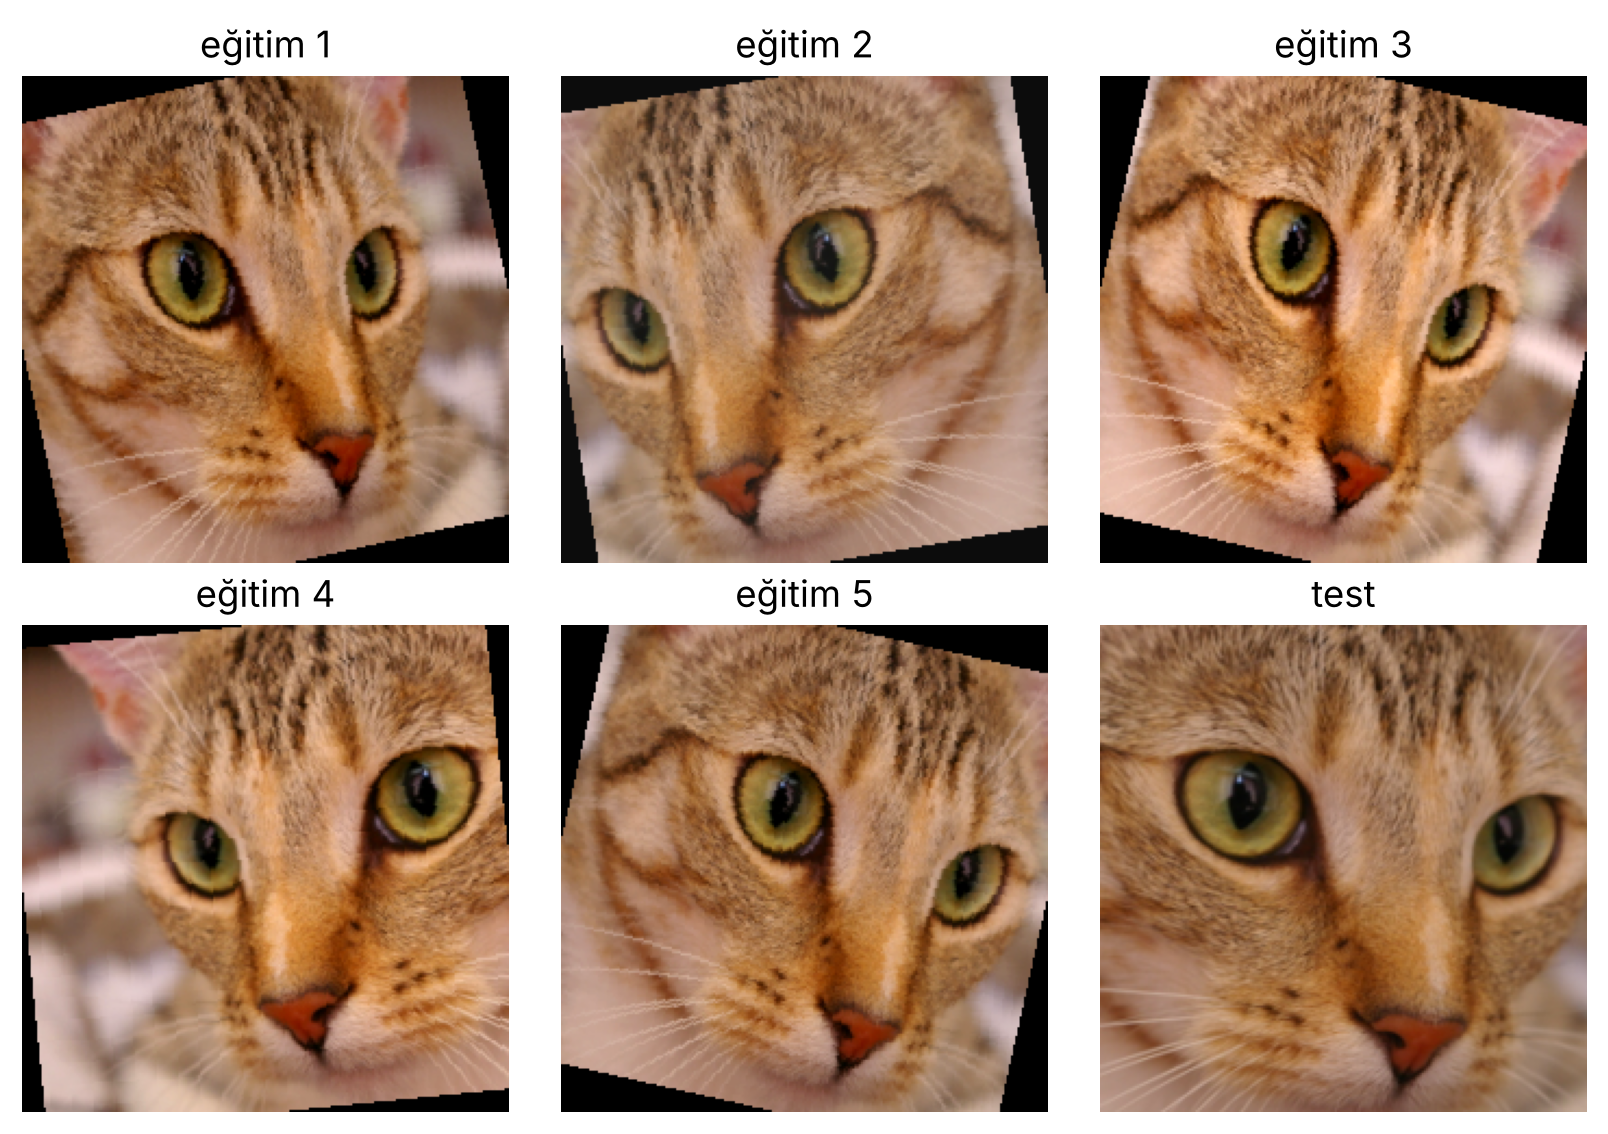

In [11]:
ORT, SS = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
egitim_donusum = transforms.Compose([   # yalnızca eğitimde
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(), transforms.Normalize(ORT, SS)])
test_donusum = transforms.Compose([     # test: sabit
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(ORT, SS)])

kedi = Image.fromarray(data.chelsea())  # örnek fotoğraf
torch.manual_seed(0)
x = [egitim_donusum(kedi) for _ in range(5)]
print(x[0].shape)                       # 3 kanal, 224 x 224
goster(x + [test_donusum(kedi)],
       [f"eğitim {i}" for i in range(1, 6)] + ["test"])

## 7. IoU, NMS ve AP
### IoU (Çözümlü Örnek 10.4)

In [12]:
def iou(a, b):                                    # (x1, y1, x2, y2)
    gx = max(0, min(a[2], b[2]) - max(a[0], b[0]))   # kesişim eni
    gy = max(0, min(a[3], b[3]) - max(a[1], b[1]))   # kesişim boyu
    alan = lambda k: (k[2] - k[0]) * (k[3] - k[1])
    return gx * gy / (alan(a) + alan(b) - gx * gy)
print(iou((50, 50, 150, 150), (70, 60, 170, 160)))   # Örnek 10.4

0.5625


### NMS (Çözümlü Örnek 10.5)

In [13]:
def nms(kutular, skorlar, esik=0.5):
    sira = sorted(range(len(skorlar)), key=lambda i: -skorlar[i])
    secilen = []
    while sira:
        i = sira.pop(0); secilen.append(i)       # en yüksek skor
        sira = [j for j in sira
                if iou(kutular[i], kutular[j]) <= esik]
    return secilen

K = {"A": (100, 100, 200, 200), "B": (110, 105, 210, 205),
     "C": (300, 120, 380, 220), "D": (95, 110, 190, 215)}
S = [0.95, 0.85, 0.80, 0.60]
print([list(K)[i] for i in nms(list(K.values()), S)])  # Örnek 10.5

['A', 'C']


### Bir sınıf için enterpolasyonlu AP (Çözümlü Örnek 10.6)

In [14]:
import numpy as np

def ap(durumlar, n_gercek):
    tp = np.cumsum([d == "TP" for d in durumlar])
    kesinlik = tp / np.arange(1, len(durumlar) + 1)
    duyarlilik = tp / n_gercek
    toplam = 0.0
    for r in np.arange(1, n_gercek + 1) / n_gercek:      # R = 1/n, 2/n, ..., 1
        uygun = kesinlik[duyarlilik >= r - 1e-9]          # R ve üzerindeki kesinlikler
        toplam += uygun.max() if len(uygun) else 0.0      # bulunamayan seviye: 0
    return toplam / n_gercek

print(ap(["TP", "TP", "FP", "TP", "FP", "FP"], 4))        # Örnek 10.6

0.6875


### Alıştırma (Değerlendirme Soruları 2, 7 ve 10)
Önce kâğıt üzerinde çözün, sonra hücreyi çalıştırıp karşılaştırın.

In [ ]:
k = nn.Conv2d(512, 128, 1)                                 # Soru 2 (bias dahil)
print("Soru 2  çıktı:", tuple(k(torch.zeros(1, 512, 14, 14)).shape), "| parametre:", say(k))
print("Soru 7  IoU:", round(iou((20, 30, 120, 130), (40, 50, 160, 150)), 3))
print("Soru 10 AP :", round(ap(["TP", "FP", "TP", "FP", "TP"], 3), 3))
print("Soru 10c AP:", round(ap(["TP", "TP", "FP", "TP"], 3), 3))